<a href="https://colab.research.google.com/github/AnshG-19/Adversarial_steganography/blob/main/notebooks/02_light_ray_trajectories.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Black Hole Simulator — Light Ray Trajectories

## Objective
Explore how light rays travel near a black hole.

## Topics
- Position and direction vectors
- Straight-line motion
- Gravitational deflection
- Numerical integration
- Comparing ray trajectories


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from scipy.integrate import solve_ivp
from scipy.optimize import brentq

print("Light ray simulation initialized.")

Light ray simulation initialized.


#Define the black hole model


In [3]:
# Geometric units: G = c = M = 1
M = 1.0

# Important radii
r_s = 2 * M
r_ph = 3 * M

# Impact parameter of the light ray
b = 8.0

# Check whether the ray is above the critical impact parameter
b_critical = 3 * np.sqrt(3) * M

print("Event horizon radius:", r_s)
print("Photon sphere radius:", r_ph)
print("Critical impact parameter:", b_critical)
print("Chosen impact parameter:", b)

Event horizon radius: 2.0
Photon sphere radius: 3.0
Critical impact parameter: 5.196152422706632
Chosen impact parameter: 8.0


Calculate the closest approach
In general relativity, the radius of closest approach \(r_0\) is related to the impact parameter by

In [4]:
def closest_approach_equation(r):
    return r**3 - b**2 * r + 2 * M * b**2


r_min = brentq(
    closest_approach_equation,
    3 * M + 1e-6,
    b
)

print("Closest approach radius:", r_min)

Closest approach radius: 6.700523482266461


#Define the light-ray equation

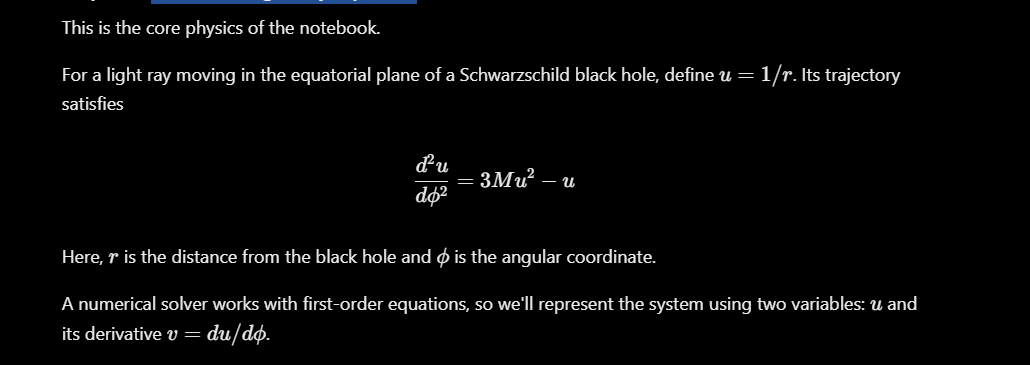

In [1]:
def light_ray_equations(phi, state):
    u, v = state

    du_dphi = v
    dv_dphi = 3 * M * u**2 - u

    return [du_dphi, dv_dphi]

#Numerically integrate the trajectory

In [5]:
initial_state = [1 / r_min, 0.0]

phi_start = 0.0
phi_end = 1.6

phi_values = np.linspace(phi_start, phi_end, 1000)

solution = solve_ivp(
    light_ray_equations,
    (phi_start, phi_end),
    initial_state,
    t_eval=phi_values,
    rtol=1e-9,
    atol=1e-11
)

u_values = solution.y[0]

# Convert inverse radius back into radius
r_values = 1 / u_values

print("Integration successful:", solution.success)
print("Number of trajectory points:", len(r_values))

Integration successful: True
Number of trajectory points: 1000


#Plot the curved ray

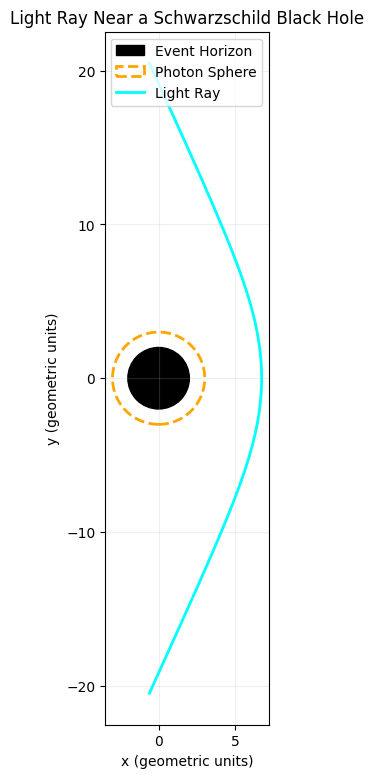

In [6]:
# Reflect the calculated path to obtain both sides
phi_full = np.concatenate((-phi_values[:0:-1], phi_values))
r_full = np.concatenate((r_values[:0:-1], r_values))

x_ray = r_full * np.cos(phi_full)
y_ray = r_full * np.sin(phi_full)

fig, ax = plt.subplots(figsize=(9, 9))

# Draw the event horizon
ax.add_patch(
    Circle((0, 0), r_s, color="black", label="Event Horizon")
)

# Draw the photon sphere
ax.add_patch(
    Circle(
        (0, 0),
        r_ph,
        fill=False,
        linestyle="--",
        linewidth=2,
        edgecolor="orange",
        label="Photon Sphere"
    )
)

# Draw the light ray
ax.plot(x_ray, y_ray, color="cyan", linewidth=2, label="Light Ray")

ax.set_aspect("equal")
ax.set_xlabel("x (geometric units)")
ax.set_ylabel("y (geometric units)")
ax.set_title("Light Ray Near a Schwarzschild Black Hole")
ax.grid(alpha=0.2)
ax.legend()

plt.show()